# Problem 13 - set 02

# Initialization

In [121]:
import numpy as np
import pandas as pd
from math import sin, pi, sqrt, exp

#data points
N = 20      #20 data points
data_points = np.zeros((N,2))
p = np.zeros(N)

for i in range(N):
    p[i] = np.random.uniform(-3, 3)
    data_points[i] = [p[i], 1+sin(p[i]*pi/3)]
    #print(f"point {i+1}: [{data_points[i]}]")

#initialize weights, biases as small random numbers

h = 4  # stands for h neurons in hidden layer and takes the value of k centers. repeat for 4,8,10
w1 = np.zeros((h,1))
b1 = np.zeros((h,1))

for i in range(h):
    w1[i] = np.random.uniform(-0.5,0.5)
    print(f"w1_{i+1} = {w1[i]} ")

    b1[i] = np.random.uniform(0,0.1)
    print(f"b1_{i+1} = {b1[i]} ")
    print()
    
#initialize parameters
a = 0.01    #learning rate

#centers
k_centers = h
c = np.zeros((k_centers,1))     #i have as many c_i as the k centers

for i in range(k_centers):
    c[i] = np.random.uniform(-3,3)
    print(f"c_{i+1} center = {c[i]}")

print()

#spreads
sigma = np.zeros((k_centers,1))
for i in range(h):
    sigma[i] = np.random.uniform(-3,3) / sqrt(2*k_centers)
    print(f"sigma_{i+1} = {sigma[i]}")
print()

#compute hidden layer activations
hidden_layer = np.zeros((k_centers,N))

for i in range(k_centers):
    for j in range(N):

        hidden_layer[i][j] = exp(- ((p[j] - c[i])**2) / (2*sigma[i]**2))
        print(f"h_{i+1}({j}) = {hidden_layer[i][j]}")
    
    print()

#compute output g(p)
output = np.zeros(N)

for i in range(N):
    for j in range(k_centers):
        output[i] += w1[j] * hidden_layer[j][i] + b1[j]
    
    print(f"output({i+1}) = {output[i]}" )

#compute loss function
loss = 0
error = np.zeros(N)

for i in range(N):
    error[i] = (data_points[i,1] - output[i])
    loss += error[i]**2

loss = loss / N
print()
print(f"loss(MSE) = {loss}")





w1_1 = [-0.01526441] 
b1_1 = [0.04755976] 

w1_2 = [-0.01719534] 
b1_2 = [0.09872015] 

w1_3 = [0.08453888] 
b1_3 = [0.02988213] 

w1_4 = [0.02184396] 
b1_4 = [0.01011918] 

c_1 center = [0.36978547]
c_2 center = [-0.43938868]
c_3 center = [-0.95838767]
c_4 center = [2.0688177]

sigma_1 = [0.94615306]
sigma_2 = [-0.77266895]
sigma_3 = [0.35547926]
sigma_4 = [0.57003291]

h_1(0) = 0.07484290665181169
h_1(1) = 0.9950090483498482
h_1(2) = 0.033798671510448366
h_1(3) = 0.007471192242123164
h_1(4) = 0.012004539781709579
h_1(5) = 0.024764328656159674
h_1(6) = 0.7854689940646811
h_1(7) = 0.18562973974544905
h_1(8) = 0.05931326148619786
h_1(9) = 0.3958756404470535
h_1(10) = 0.275834264123234
h_1(11) = 0.47986406475420024
h_1(12) = 0.12779043081222088
h_1(13) = 0.6789496006247994
h_1(14) = 0.6627759227886082
h_1(15) = 0.30314642930360025
h_1(16) = 0.8482246621019893
h_1(17) = 0.31780096520463985
h_1(18) = 0.94242989551411
h_1(19) = 0.9652413815773447

h_2(0) = 0.2196896526102408
h_2(1) = 0.5045

C:\Users\user\AppData\Local\Temp\ipykernel_16784\3455392518.py:55: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  hidden_layer[i][j] = exp(- ((p[j] - c[i])**2) / (2*sigma[i]**2))
C:\Users\user\AppData\Local\Temp\ipykernel_16784\3455392518.py:65: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  output[i] += w1[j] * hidden_layer[j][i] + b1[j]


# update gradients - training

In [122]:
#update parameters using gradient descent

#update gradient weights
gradient_weights = np.zeros(k_centers)

for i in range(k_centers):
    for j in range(N):
        gradient_weights[i] += error[j]*hidden_layer[i][j]
    
    gradient_weights[i] = -2*gradient_weights[i] / N

    print(f"dw_{i+1} = {gradient_weights[i]}")

print()

#update gradient with respect to centers c_i
gradient_centers = np.zeros(N)

for i in range(k_centers):
    for j in range(N):
        gradient_centers[i] += error[j]*w1[i]*hidden_layer[i][j]* (p[j] - c[i])/(sigma[i])**2

    gradient_centers[i] = -2 * gradient_centers[i] / N
    
    print(f"dc_{i+1} = {gradient_centers[i]}")

print()

#update gradient with respect to sigma
gradient_sigma = np.zeros(N)

for i in range(k_centers):
    for j in range(N):
        gradient_sigma[i] += error[j]*w1[i]*hidden_layer[i][j]* (p[j] - c[i])**2 / (sigma[i])**3

    gradient_sigma[i] = -2 * gradient_sigma[i] / N

    print(f"dsigma_{i+1} = {gradient_sigma[i]}")

print()

#update gradient with respect to biases
gradient_bias = 0

for j in range(N):
    gradient_bias += error[j]

gradient_bias = -2 * gradient_bias / N
print(f"db = {gradient_bias}")


dw_1 = -0.6869497337179993
dw_2 = -0.3152322439453902
dw_3 = 0.020541171881829617
dw_4 = -0.40266783751563573

dc_1 = 0.004009358605678323
dc_2 = 0.007384068814277755
dc_3 = -0.01688030927068804
dc_4 = 0.004158334103292126

dsigma_1 = 0.0059858934450456236
dsigma_2 = -0.007550307485071443
dsigma_3 = -0.01217646439914329
dsigma_4 = -0.01346769107752813

db = -1.1344980759104586


C:\Users\user\AppData\Local\Temp\ipykernel_16784\445803920.py:21: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gradient_centers[i] += error[j]*w1[i]*hidden_layer[i][j]* (p[j] - c[i])/(sigma[i])**2
C:\Users\user\AppData\Local\Temp\ipykernel_16784\445803920.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gradient_sigma[i] += error[j]*w1[i]*hidden_layer[i][j]* (p[j] - c[i])**2 / (sigma[i])**3


# update parameters for layer 2

In [124]:
w2 = np.zeros(k_centers)
c2 = np.zeros(k_centers)
sigma_2 = np.zeros(k_centers)
b2 = 0

#update
for i in range(k_centers):
    w2[i] -= a * gradient_weights[i]
    c2[i] -= a * gradient_centers[i]
    sigma_2[i] -= a * gradient_sigma[i]

b2 = - a * gradient_bias

for i in range(k_centers):
    print(f"w2_{i+1} = {w2[i]}")
    print(f"c2_{i+1} = {c2[i]}")
    print(f"sigma2_{i+1} = {sigma_2[i]}")

    print()

print()
print(f"b2 = {b2}")




w2_1 = 0.0006869497337179993
c2_1 = -4.009358605678323e-06
sigma2_1 = -5.985893445045623e-06

w2_2 = 0.0003152322439453902
c2_2 = -7.3840688142777556e-06
sigma2_2 = 7.550307485071443e-06

w2_3 = -2.0541171881829616e-05
c2_3 = 1.688030927068804e-05
sigma2_3 = 1.217646439914329e-05

w2_4 = 0.0004026678375156357
c2_4 = -4.158334103292127e-06
sigma2_4 = 1.346769107752813e-05


b2 = 0.0011344980759104585


# find final output using updated weights

In [125]:
final_output = np.zeros(N)

final_output = np.zeros(N)

for i in range(N):
    for j in range(k_centers):
        final_output[i] += w2[j] * hidden_layer[j][i] + b2
    
    print(f"a2_({i+1}) = {final_output[i]}" )

a2_(1) = 0.004657279825912589
a2_(2) = 0.005388217579231537
a2_(3) = 0.004593014775616862
a2_(4) = 0.004549649187162815
a2_(5) = 0.004557121410941152
a2_(6) = 0.00467925539091349
a2_(7) = 0.005383401867878998
a2_(8) = 0.00480832370713907
a2_(9) = 0.004633566629082975
a2_(10) = 0.005049675552727888
a2_(11) = 0.004916505788325512
a2_(12) = 0.005136175891963987
a2_(13) = 0.005000108670207264
a2_(14) = 0.005164226640924307
a2_(15) = 0.005299332378246564
a2_(16) = 0.005119704293849989
a2_(17) = 0.005240355873807005
a2_(18) = 0.004964277191014211
a2_(19) = 0.005444953473348152
a2_(20) = 0.005444995971025649


# plot the network and the training points

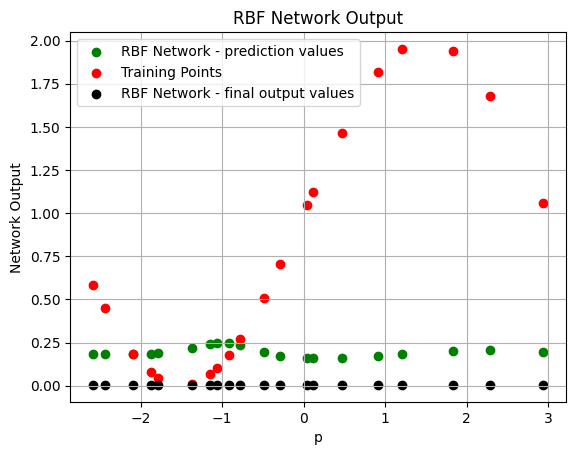

In [126]:
import matplotlib.pyplot as plt

#plt.plot(p, output, label='RBF Network', color='green')
plt.scatter(p,output,color='green',label='RBF Network - prediction values')
plt.scatter(p, 1 + np.sin(p * np.pi / 3), color='red', label='Training Points')
plt.scatter(p,final_output,color='black',label='RBF Network - final output values')
plt.title('RBF Network Output')
plt.xlabel('p')
plt.ylabel('Network Output')
plt.legend()
plt.grid(True)
plt.show()